In [1]:
import scipy.io as sio
import pickle
import matplotlib.pyplot as plt
import numpy as np
import sys
import pandas as pd
import seaborn as sns
sys.path.append('../../')
from helper_function import *
cobra.Configuration.solver = "glpk"
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12
set_panel_style(scale=4)

In [2]:
cmap = plt.get_cmap('coolwarm')
num_colors = 20
colors = [cmap(i / num_colors) for i in range(num_colors)]

set_color = colors[19] #17 18
scatter_color = colors[18] #3 2

model = cobra.io.load_matlab_model("../../universal_model.mat")

with open('../../FBAsolution/M9_sufficient_423_1_proteome_weakbg.pkl', 'rb') as pickle_file:
    data = pickle.load(pickle_file)
    all_total_nutrient_count = data['all_total_nutrient_count']
    all_total_intake = data['all_total_intake']
    all_growth_rate = data['all_growth_rate']
    all_random_medium = data['all_random_medium']
    all_met_flux = data['all_met_flux']
    del data

In [4]:
model_properties_df = pd.read_csv("model_properties.csv")

In [ ]:
total_slope = []
all_carbon_flux = []
for met_flux in all_met_flux[0]:
    all_carbon_flux.append(carbon_input_flux(met_flux, model))
all_carbon_flux = np.array(all_carbon_flux)

plt.figure(figsize=(8, 8))

for i in [0]:
    mask = (all_growth_rate[i] > 0.001) & (all_carbon_flux < 1500)
    x = all_carbon_flux[mask]
    y = (all_growth_rate[i])[mask]

    if len(x) < 2:
        continue

    try:
        plt.scatter(
            x, y,
            color=scatter_color,
            #label="Monocultures",
            s=200,          
            edgecolors="none"
        )

        # Fit line
        slope, intercept = np.polyfit(x, y, 1)
        print(pearson_ci(x, y, confidence=0.95))

        xmin = 0
        xmax = float(np.max(x))
        xx = np.linspace(xmin, xmax, 200)
        yy = slope * xx + intercept

        plt.plot(xx, yy, color=set_color, alpha=0.7)
        total_slope.append(slope)

    except Exception:
        continue

plt.xlim((0, float(np.max(x)) + 50))
plt.ylim((0, 5))

plt.legend(frameon=False, handletextpad=0.1)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


plt.tight_layout()

#plt.savefig("Supp_Figure2_a.pdf", format="pdf", pad_inches=0.5)

plt.show()
plt.close()

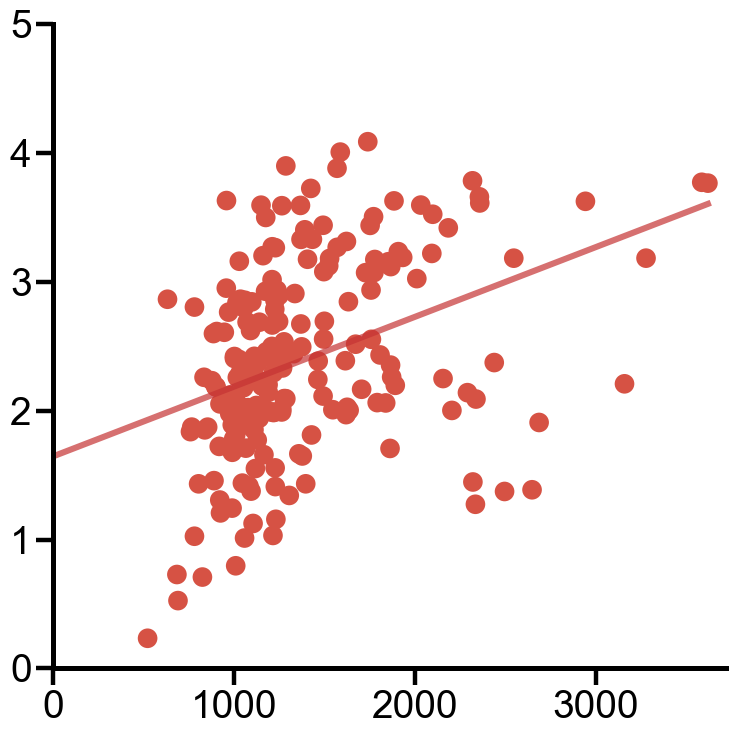

{'r': 0.3798731657822063,
 'p': 2.4619481655385365e-08,
 'ci_low': 0.25520562556831394,
 'ci_high': 0.492116648763557,
 'n': 202}

In [ ]:
plt.figure(figsize=(8, 8))
x = (model_properties_df['Number of reactions'])[all_growth_rate[0] > 0.001]
y = (all_growth_rate[0])[all_growth_rate[0] > 0.001]

slope, intercept = np.polyfit(x, y, 1)
xmin = 0
xmax = int(np.ceil(np.max(x)))
xx = np.arange(xmin, xmax + 1)
yy = slope * xx + intercept
plt.plot(xx, yy, color=set_color, alpha=0.7) 

plt.scatter(x, y, color=scatter_color, s=200, edgecolor='None')
#plt.xticks([0, 100, 200, 300, 400, 500])
plt.xlim((0, int(np.ceil(xmax) + 100)))
plt.ylim(0, 5)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()

#plt.savefig("Supp_Figure2_b.pdf", format="pdf", pad_inches=0.5)
plt.show()
pearson_ci(x, y)

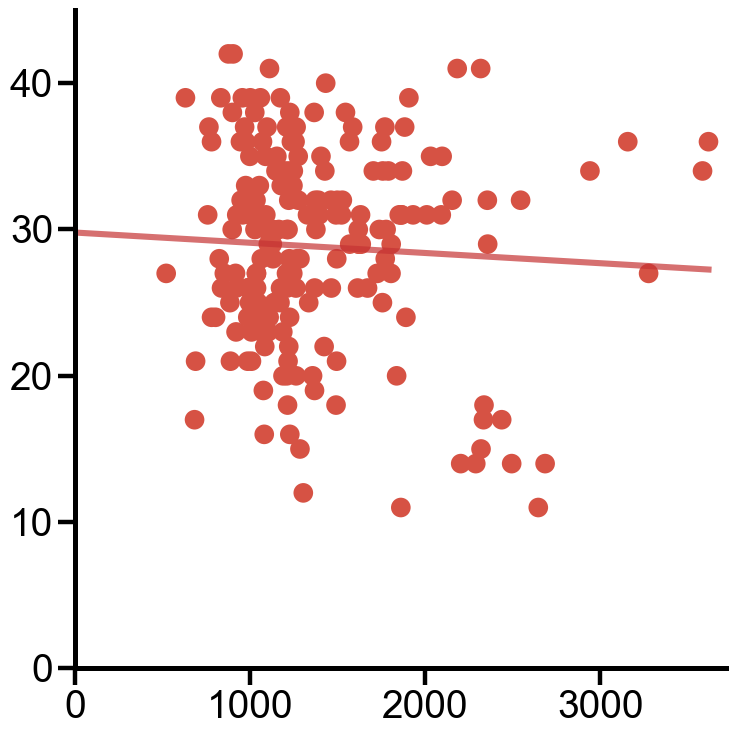

{'r': -0.05500930111556806,
 'p': 0.4368248103518494,
 'ci_low': -0.19160523451741032,
 'ci_high': 0.08367715124099973,
 'n': 202}

In [ ]:
plt.figure(figsize=(8, 8))
x = (model_properties_df['Number of reactions'])[all_growth_rate[0] > 0.001]
y = (all_total_nutrient_count[0])[all_growth_rate[0] > 0.001]

slope, intercept = np.polyfit(x, y, 1)
xmin = 0
xmax = int(np.ceil(np.max(x)))
xx = np.arange(xmin, xmax + 1)
yy = slope * xx + intercept
plt.plot(xx, yy, color=set_color, alpha=0.7) 

plt.scatter(x, y, color=scatter_color, s=200, edgecolor='None')

plt.xlim((0, int(np.ceil(xmax) + 100)))

plt.ylim(0, 45)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()

#plt.savefig("Supp_Figure2_c.pdf", format="pdf", pad_inches=0.5)
plt.show()
pearson_ci(x, y)